# 02: Score outputs with Ray Data

Generated video needs checking at scale. This notebook runs the quality pass live on CPU over the bundled outputs, then compares it with the stored results of the full 288-clip run.

* **Edge F1** compares the edges of each output with those of the source clip within 2 pixels and measures how much of the original structure is preserved.
* **Temporal checks** look for blank frames, frozen frames and sudden jumps.
* **Color** compares brightness and chroma with the source.

In [1]:
# Setup
USE_GPUS = False   # False: stored results on CPU. True: generate live on GPUs (template image + weights).

import os, sys
sys.path.insert(0, os.getcwd())
import pandas as pd
import notebook_helpers as nh

pd.set_option("display.max_colwidth", 80)
nh.check_setup(USE_GPUS)

COSMOS_SHARED = /mnt/user_storage/cosmos-video-augmentation  (99 videos in the bundle)
Mode: stored results on CPU (set USE_GPUS = True to generate)


In [2]:
import logging, ray
from offroad_ray.ray_env import init_ray
init_ray()
ray.data.DataContext.get_current().enable_progress_bars = False
logging.getLogger("ray.data").setLevel(logging.WARNING)

rows = []
for sid, s in nh.scenes().items():
    for cond in s["conditions"]:
        rows.append({"request_id": f"{sid}-{cond}", "scene": s["label"], "condition": cond,
                     "status": "generated_unreviewed",
                     "output_path": str(nh.MEDIA / sid / f"{cond}.mp4"), "clip_path": str(nh.MEDIA / sid / "src.mp4")})
print(len(rows), "outputs to score")

90 outputs to score


The same function the batch pipeline uses, mapped over every output with Ray Data. Each worker decodes its own videos, so only paths travel through the pipeline:

In [3]:
from offroad_ray.quality.metrics import compute_output_metrics

ds = ray.data.from_items(rows, override_num_blocks=len(rows))
metrics = ds.map(compute_output_metrics, num_cpus=1).to_pandas()
scored = pd.DataFrame(rows).merge(metrics, on="request_id")
scored.groupby("condition")[["edge_f1", "frozen_frames", "blank_frames"]].mean().round(3).sort_values("edge_f1")

2026-11-19 22:52:41,656	WARNING __init__.py:28 -- Progress bars disabled. To enable, set `ray.data.DataContext.get_current().enable_progress_bars = True`.


,edge_f1,frozen_frames,blank_frames
condition,,,
wildfire_smoke,0.494,3.556,0.0
blizzard_whiteout,0.561,4.667,0.0
night,0.627,6.111,0.0
blue_hour_dusk,0.653,2.778,0.0
dust_brownout,0.714,1.444,0.0
night_rain,0.715,3.222,0.0
golden_hour_glare,0.719,4.0,0.0
rain,0.783,1.444,0.0
drought_summer,0.784,0.778,0.0


The bundled videos are re-encoded copies, so values differ slightly from the originals. The full run scored the original outputs, 72 per condition:

In [4]:
full = pd.read_csv(nh.RESULTS / "main" / "quality" / "condition_summary.csv")
full = full.rename(columns={"count()": "outputs", "mean(edge_f1)": "edge_f1", "mean(delta_luma)": "change_in_brightness",
                            "sum(blank_frames)": "blank_frames"})
full[["condition", "outputs", "edge_f1", "change_in_brightness", "blank_frames"]].round(3).sort_values("edge_f1")

,condition,outputs,edge_f1,change_in_brightness,blank_frames
1,fog,72,0.529,7.827,0
3,night,72,0.640,-82.403,0
2,rain,72,0.779,-33.879,0
0,snow,72,0.820,17.261,0


## Measuring color on dark frames

HSV saturation is normalized by brightness, so it rises sharply on dark night frames even when the frame holds no more color. CIELAB chroma does not depend on brightness. On this drive, the night version measures far higher in HSV saturation while its CIELAB chroma stays close to the real clip; golden hour adds real color and rises in both:

In [5]:
import cv2, numpy as np

def color_stats(path):
    cap, hsv_s, chroma = cv2.VideoCapture(str(path)), [], []
    for i in range(0, 93, 8):
        cap.set(cv2.CAP_PROP_POS_FRAMES, i)
        ok, f = cap.read()
        if not ok:
            break
        hsv_s.append(cv2.cvtColor(f, cv2.COLOR_BGR2HSV)[..., 1].mean())
        lab = cv2.cvtColor(f, cv2.COLOR_BGR2LAB).astype(np.float32)
        chroma.append(np.hypot(lab[..., 1] - 128, lab[..., 2] - 128).mean())
    return {"HSV saturation": round(float(np.mean(hsv_s)), 1), "CIELAB chroma": round(float(np.mean(chroma)), 2)}

sid = "5d20270fcc"
pd.DataFrame({c: color_stats(nh.MEDIA / sid / f"{c}.mp4") for c in ("src", "night", "golden_hour_glare")}).T

,HSV saturation,CIELAB chroma
src,37.0,8.76
night,132.2,8.10
golden_hour_glare,207.5,35.27


Over the full run (24 source clips and 96 outputs, every 8th frame), the same comparison:

In [6]:
sat = nh.read_json(nh.RESULTS / "main" / "quality" / "saturation_check.json")["by_condition"]
pd.DataFrame(sat).T.rename(columns={"hsv_s": "HSV saturation", "lab_chroma": "CIELAB chroma",
                                    "v_mean": "brightness"})[["brightness", "HSV saturation", "CIELAB chroma"]]

,brightness,HSV saturation,CIELAB chroma
fog,136.37,39.66,7.57
night,48.16,170.70,15.44
rain,96.22,83.90,12.28
snow,141.82,21.84,3.87
source,122.50,41.83,8.47


## An automated judge, and its limits

The study also asked a vision-language model, Cosmos-Reason1-7B, to rate every clip without telling it the requested condition. Its scores were useful to rank showcase candidates, but it is weak evidence: it labeled most rain clips "overcast". Use human review for any claim about realism.

In [7]:
judge = nh.read_json(nh.RESULTS / "judge" / "main" / "summary.json")
pd.DataFrame(judge["by_set_condition"]).query("set == 'main'")[
    ["requested_condition", "n", "photorealism", "temporal_stability", "physical_plausibility", "condition_match"]]

,requested_condition,n,photorealism,temporal_stability,physical_plausibility,condition_match
0,fog,71,4.35,4.01,4.48,0.464789
1,night,71,4.61,4.38,4.68,0.971831
2,rain,71,4.41,4.28,4.57,0.042254
3,snow,71,4.33,4.34,4.46,0.197183


## Failure cases

Automatic flags point to clips for manual review. In the full run, all 6 flags were frozen frames from one slow-moving source clip, which already repeats frames because 10 Hz footage is stretched to 16 fps.

In [8]:
qt = pd.read_parquet(nh.RESULTS / "main" / "quality" / "quality_table.parquet")
flagged = qt[qt["auto_flags"].fillna("") != ""]
print(f"{len(flagged)} of {len(qt)} outputs flagged")
flagged[["clip_id", "condition", "seed", "auto_flags", "frozen_frames", "source_frozen_frames"]]

6 of 288 outputs flagged


,clip_id,condition,seed,auto_flags,frozen_frames,source_frozen_frames
6,2023-11-14-14-26-22_gupta__image_left_color__t164.446__08cdd3d5,fog,303,frozen_frames,66,49
62,2023-11-14-14-26-22_gupta__image_left_color__t164.446__08cdd3d5,night,101,frozen_frames,70,49
122,2023-11-14-14-26-22_gupta__image_left_color__t164.446__08cdd3d5,night,303,frozen_frames,67,49
231,2023-11-14-14-26-22_gupta__image_left_color__t164.446__08cdd3d5,fog,101,frozen_frames,65,49
244,2023-11-14-14-26-22_gupta__image_left_color__t164.446__08cdd3d5,fog,202,frozen_frames,70,49
246,2023-11-14-14-26-22_gupta__image_left_color__t164.446__08cdd3d5,night,202,frozen_frames,70,49


The lowest-scoring output of the study: wildfire smoke, where the sun disc dissolves and smoke appears and vanishes between frames.

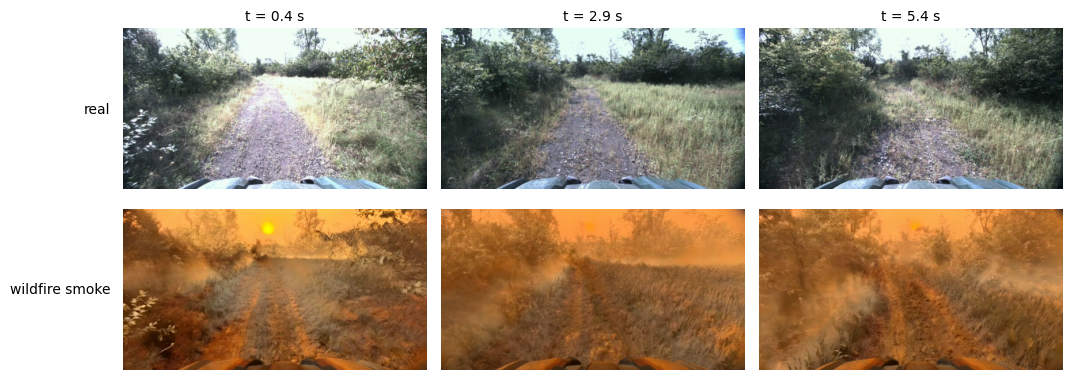

In [9]:
sid = "833f53f9d2"
nh.show_strip([nh.MEDIA / sid / "src.mp4", nh.MEDIA / sid / "wildfire_smoke.mp4"], ["real", "wildfire smoke"])